# 05 · Torneo de modelos — AccessGuard AI

**Objetivo:** elegir **dos finalistas** para optimizar, con evidencia y sin tocar la reserva ni `test.csv`.

Reglas del torneo:
1. **Mismos datos y misma validación para todos:** 5 pliegues `StratifiedGroupKFold` — estratificados por `ACTION` (para manejar el desbalance 94/6) **y agrupados por gerente** (`MGR_ID`),
   porque un mismo gerente en entrenamiento y validación inflaría los resultados. Es la versión de `StratifiedKFold` que respeta la regla de la partición por gerente.
2. **Un punto de referencia (baseline)** que todo modelo serio debe vencer: regresión logística L2.
3. **Mirar la variabilidad entre pliegues**, no solo el promedio.
4. Las variables (notebook 04) se calculan **dentro de cada pliegue**, solo con su entrenamiento.

| Candidato | Por qué está |
|---|---|
| Regresión logística L2 | Baseline interpretable |
| Regresión logística ElasticNet | Baseline con selección de variables (L1 + L2) |
| Random Forest | Ensamble de árboles independientes, robusto |
| XGBoost / LightGBM / CatBoost | Boosting, el estándar en datos tabulares |

> **Convención:** clase positiva = 1 = *aprobar*. Como la clase **denegar** (5,8 %) es la que importa y la minoritaria, se reportan **ROC-AUC** y **PR-AUC de *denegar***
> (PR-AUC de *aprobar* se muestra aparte: con 94 % de positivos casi siempre es alta y engaña). Nunca se usa accuracy sola.

In [1]:
import sys, warnings, json, time
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config.settings import PROCESSED_DIR, REPORTS_DIR, SEED, TARGET, GROUP_COL, COST_FP, COST_FN
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Datos y pliegues

Solo `train_clean.csv`. La reserva (`holdout`) y `test.csv` no se leen en este notebook.

In [2]:
from accessguard.modeling import MODEL_NAMES, build_model, fold_matrices, make_cv, metrics_at, best_threshold, expected_cost

train = pd.read_csv(PROCESSED_DIR / "train_clean.csv")
y = train[TARGET].to_numpy()
X = train.drop(columns=TARGET)
cv = make_cv(5, SEED)

# integridad: ningún gerente en dos pliegues de validación a la vez, y la tasa de "denegar" es parecida
seen = []
for k, (tr, va) in enumerate(cv.split(X, y, groups=X[GROUP_COL])):
    assert not set(X[GROUP_COL].iloc[tr]) & set(X[GROUP_COL].iloc[va]), "fuga por gerente"
    seen.append({"pliegue": k, "filas val": len(va), "gerentes val": X[GROUP_COL].iloc[va].nunique(), "% denegar (val)": 100 * (1 - y[va].mean())})
print("Sin gerentes compartidos entre entrenamiento y validación en los 5 pliegues.")
pd.DataFrame(seen).round(2)

Sin gerentes compartidos entre entrenamiento y validación en los 5 pliegues.


,pliegue,filas val,gerentes val,% denegar (val)
0,0,5243,674,5.78
1,1,5239,662,5.80
2,2,5247,672,5.81
3,3,5243,671,5.78
4,4,5243,681,5.78


In [3]:
t0 = time.time()
folds = fold_matrices(X, y, X[GROUP_COL], cv, seed=SEED)      # variables de cada pliegue, calculadas una vez
print(f"{len(folds)} pliegues · {folds[0][0].shape[1]} variables · {time.time() - t0:.1f} s")

5 pliegues · 29 variables · 6.4 s


## 2. Correr el torneo

Cada modelo se entrena con el entrenamiento de cada pliegue y predice la probabilidad de *aprobar* en el pliegue de validación.
Guardamos las **predicciones fuera de pliegue (OOF)** de todas las filas y las métricas de **cada pliegue** (no solo el promedio).

In [4]:
fold_rows, oof = [], {}
for name in MODEL_NAMES:
    p_oof = np.zeros(len(y)); t0 = time.time()
    for k, (X_tr, y_tr, X_va, y_va, idx_va) in enumerate(folds):
        model = build_model(name, seed=SEED).fit(X_tr, y_tr)
        p = model.predict_proba(X_va)[:, 1]
        p_oof[idx_va] = p
        m = metrics_at(y_va, p, 0.5)
        fold_rows.append({"modelo": name, "pliegue": k, "roc_auc": m["roc_auc"], "pr_auc_deny": m["pr_auc_deny"], "pr_auc_approve": m["pr_auc_approve"]})
    oof[name] = p_oof
    print(f"{name:24s} listo en {time.time() - t0:5.1f} s")
fold_df = pd.DataFrame(fold_rows)

LogReg L2 (baseline)     listo en   0.3 s


LogReg ElasticNet        listo en   3.4 s


Random Forest            listo en   6.6 s


XGBoost                  listo en   1.8 s


LightGBM                 listo en   2.2 s


CatBoost                 listo en  13.4 s


## 3. Tabla comparativa: ROC-AUC y PR-AUC (media ± desviación entre pliegues)

El **ranking** combina ambas métricas: posición media en ROC-AUC y en PR-AUC de *denegar* (menor = mejor). Los dos primeros son los finalistas.

In [5]:
g = fold_df.groupby("modelo")
table = pd.DataFrame({
    "ROC-AUC": g.roc_auc.mean(), "± ROC": g.roc_auc.std(),
    "PR-AUC denegar": g.pr_auc_deny.mean(), "± PR": g.pr_auc_deny.std(),
    "PR-AUC aprobar": g.pr_auc_approve.mean(),
})
table["rank ROC"] = table["ROC-AUC"].rank(ascending=False)
table["rank PR"] = table["PR-AUC denegar"].rank(ascending=False)
table["rank medio"] = (table["rank ROC"] + table["rank PR"]) / 2
table = table.sort_values(["rank medio", "ROC-AUC"], ascending=[True, False])
table["finalista"] = ["★" if i < 2 else "" for i in range(len(table))]
print("Referencia azar: ROC-AUC = 0.5 · PR-AUC denegar = tasa de 'denegar' =", round(1 - y.mean(), 4))
table.round(4)

Referencia azar: ROC-AUC = 0.5 · PR-AUC denegar = tasa de 'denegar' = 0.0579


,ROC-AUC,± ROC,PR-AUC denegar,± PR,PR-AUC aprobar,rank ROC,rank PR,rank medio,finalista
modelo,,,,,,,,,
LogReg ElasticNet,0.7331,0.0080,0.1849,0.0154,0.9755,1.0,3.0,2.0,★
LogReg L2 (baseline),0.7330,0.0085,0.1850,0.0156,0.9755,2.0,2.0,2.0,★
Random Forest,0.7257,0.0165,0.1955,0.0306,0.9744,3.0,1.0,2.0,
CatBoost,0.7111,0.0160,0.1756,0.0261,0.9732,4.0,4.0,4.0,
XGBoost,0.7077,0.0227,0.1735,0.0241,0.9726,5.0,5.0,5.0,
LightGBM,0.7013,0.0310,0.1694,0.0229,0.9721,6.0,6.0,6.0,


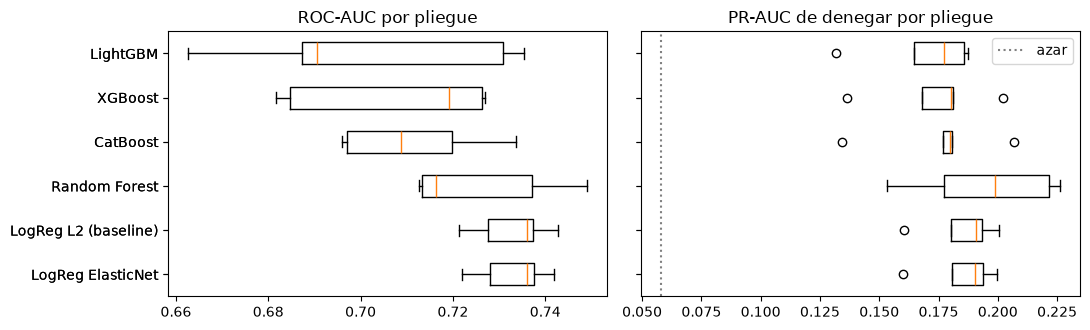

In [6]:
order = list(table.index)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, col, title in zip(axes, ["roc_auc", "pr_auc_deny"], ["ROC-AUC por pliegue", "PR-AUC de denegar por pliegue"]):
    ax.boxplot([fold_df.loc[fold_df.modelo == n, col] for n in order], vert=False, tick_labels=order, widths=0.5)
    ax.set_title(title); ax.invert_yaxis()
axes[1].axvline(1 - y.mean(), color="grey", ls=":", label="azar"); axes[1].legend()
plt.tight_layout(); plt.show()

## 4. F1, recall y matriz de confusión

ROC-AUC y PR-AUC miden qué tan bien **ordena** el modelo; F1, recall y la matriz de confusión dependen de **dónde se pone el umbral**. Se muestran en dos umbrales, sobre las predicciones OOF (todas las filas, cada una predicha por un modelo que no la vio):

* **0,5** — el umbral por defecto, solo como referencia (con 94 % de *aprobar* casi no deniega nada);
* **umbral de menor costo** (supuestos `COST_FP` / `COST_FN` de `config/settings.py`): *aprobar si p ≥ umbral*. **Son supuestos a validar con Seguridad/Riesgos, no costos medidos.**

In [7]:
print(f"Supuestos: FP (acceso indebido) = {COST_FP:,.0f} USD · FN (usuario legítimo bloqueado) = {COST_FN:,.0f} USD")
rows, conf = [], {}
for name in order:
    t_star, c_star, _ = best_threshold(y, oof[name], COST_FP, COST_FN)
    for label, thr in [("0.5", 0.5), ("óptimo", t_star)]:
        m = metrics_at(y, oof[name], thr)
        rows.append({"modelo": name, "umbral": label, "valor umbral": round(thr, 3), "F1 denegar": m["f1_deny"], "recall denegar": m["recall_deny"],
                     "F1 aprobar": m["f1_approve"], "recall aprobar": m["recall_approve"],
                     "costo/solicitud (USD)": expected_cost(y, oof[name], thr, COST_FP, COST_FN)})
        if label == "óptimo":
            conf[name] = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
thr_table = pd.DataFrame(rows)
thr_table.round(4)

Supuestos: FP (acceso indebido) = 2,000 USD · FN (usuario legítimo bloqueado) = 40 USD


,modelo,umbral,valor umbral,F1 denegar,recall denegar,F1 aprobar,recall aprobar,costo/solicitud (USD)
0,LogReg ElasticNet,0.5,0.500,0.1510,0.0975,0.9670,0.9881,104.9689
1,LogReg ElasticNet,óptimo,0.950,0.1314,0.9460,0.3789,0.2345,35.1020
2,LogReg L2 (baseline),0.5,0.500,0.1493,0.0955,0.9673,0.9887,105.1764
3,LogReg L2 (baseline),óptimo,0.955,0.1298,0.9513,0.3580,0.2187,35.0883
4,Random Forest,0.5,0.500,0.0156,0.0079,0.9703,0.9998,114.9037
5,Random Forest,óptimo,0.950,0.1270,0.9559,0.3251,0.1946,35.4606
6,CatBoost,0.5,0.500,0.0431,0.0224,0.9703,0.9989,113.2573
7,CatBoost,óptimo,0.990,0.1217,0.9743,0.2406,0.1369,35.4988
8,XGBoost,0.5,0.500,0.0427,0.0224,0.9700,0.9983,113.2802
9,XGBoost,óptimo,0.985,0.1240,0.9605,0.2873,0.1682,35.9245


In [8]:
# referencia: aprobar todo y denegar todo (sin modelo)
ref = pd.DataFrame({"estrategia": ["aprobar todo", "denegar todo"],
                    "costo/solicitud (USD)": [expected_cost(y, np.ones(len(y)), 0.5, COST_FP, COST_FN), expected_cost(y, np.zeros(len(y)), 0.5, COST_FP, COST_FN)]})
print(ref.round(2).to_string(index=False))
best_cost = thr_table[thr_table["umbral"] == "óptimo"].sort_values("costo/solicitud (USD)").iloc[0]
print(f"\nMejor costo con umbral óptimo: {best_cost['modelo']} = {best_cost['costo/solicitud (USD)']:.2f} USD por solicitud")

  estrategia  costo/solicitud (USD)
aprobar todo                 115.81
denegar todo                  37.68

Mejor costo con umbral óptimo: LogReg L2 (baseline) = 35.09 USD por solicitud


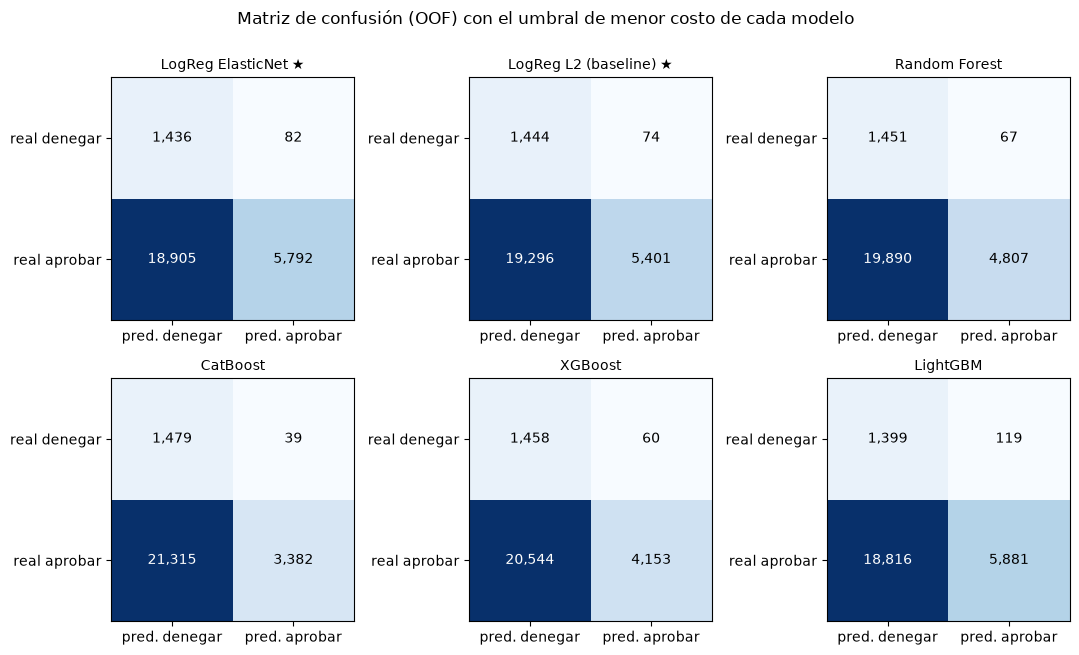

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, name in zip(axes.ravel(), order):
    cm = conf[name]
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["pred. denegar", "pred. aprobar"]); ax.set_yticks([0, 1], ["real denegar", "real aprobar"])
    ax.set_title(name + (" ★" if name in order[:2] else ""), fontsize=10)
plt.suptitle("Matriz de confusión (OOF) con el umbral de menor costo de cada modelo", y=1.0); plt.tight_layout(); plt.show()

**Cómo leerlo.** La fila "real denegar / pred. aprobar" son los **accesos indebidos concedidos (FP)**: el error caro. Un modelo con un umbral que casi no deniega puede tener buen *accuracy* y ser inútil para seguridad;
por eso se compara el costo y el recall de *denegar*, no el accuracy.

## 5. ¿La diferencia entre los mejores es real?

Los modelos se evaluaron en **los mismos pliegues**, así que se pueden comparar de a pares: diferencia de ROC-AUC pliegue a pliegue entre los dos finalistas y el resto.

In [10]:
wide = fold_df.pivot(index="pliegue", columns="modelo", values="roc_auc")
top = order[:2]
rows = []
for other in order:
    if other == top[0]:
        continue
    d = wide[top[0]] - wide[other]
    rows.append({"líder": top[0], "contra": other, "dif. media ROC-AUC": d.mean(), "pliegues que gana": f"{(d > 0).sum()} de {len(d)}",
                 "dif. / desv. entre pliegues": d.mean() / d.std(ddof=1) if d.std(ddof=1) > 0 else np.inf})
pd.DataFrame(rows).round(4)

,líder,contra,dif. media ROC-AUC,pliegues que gana,dif. / desv. entre pliegues
0,LogReg ElasticNet,LogReg L2 (baseline),0.0001,3 de 5,0.1231
1,LogReg ElasticNet,Random Forest,0.0074,3 de 5,0.4135
2,LogReg ElasticNet,CatBoost,0.0221,4 de 5,1.1107
3,LogReg ElasticNet,XGBoost,0.0254,4 de 5,1.0444
4,LogReg ElasticNet,LightGBM,0.0318,4 de 5,1.0122


Una diferencia que **gana en los 5 pliegues** y es varias veces mayor que su desviación es consistente; si gana en 3 de 5 y la razón es < 1, es un **empate práctico**: con estos datos no se puede asegurar quién es mejor.

## 6. Finalistas y registro de resultados

In [11]:
finalists = list(table.index[:2])
summary = table.reset_index().rename(columns={"index": "modelo"})
summary = summary.merge(thr_table[thr_table["umbral"] == "óptimo"][["modelo", "F1 denegar", "recall denegar", "costo/solicitud (USD)"]], on="modelo")
summary.to_csv(REPORTS_DIR / "05_torneo_tabla.csv", index=False)
thr_table.to_csv(REPORTS_DIR / "05_torneo_umbrales.csv", index=False)
(REPORTS_DIR / "05_finalistas.json").write_text(json.dumps({
    "criterio": "posición media en ROC-AUC y PR-AUC (denegar), 5 pliegues StratifiedGroupKFold por MGR_ID",
    "finalistas": finalists, "mejor": finalists[0], "seed": SEED, "n_splits": 5,
    "roc_auc": {n: float(table.loc[n, "ROC-AUC"]) for n in table.index},
    "pr_auc_deny": {n: float(table.loc[n, "PR-AUC denegar"]) for n in table.index},
}, indent=2, ensure_ascii=False), encoding="utf-8")
print("Finalistas:", finalists)
summary.round(4)

Finalistas: ['LogReg ElasticNet', 'LogReg L2 (baseline)']


,modelo,ROC-AUC,± ROC,PR-AUC denegar,± PR,PR-AUC aprobar,rank ROC,rank PR,rank medio,finalista,F1 denegar,recall denegar,costo/solicitud (USD)
0,LogReg ElasticNet,0.7331,0.0080,0.1849,0.0154,0.9755,1.0,3.0,2.0,★,0.1314,0.9460,35.1020
1,LogReg L2 (baseline),0.7330,0.0085,0.1850,0.0156,0.9755,2.0,2.0,2.0,★,0.1298,0.9513,35.0883
2,Random Forest,0.7257,0.0165,0.1955,0.0306,0.9744,3.0,1.0,2.0,,0.1270,0.9559,35.4606
3,CatBoost,0.7111,0.0160,0.1756,0.0261,0.9732,4.0,4.0,4.0,,0.1217,0.9743,35.4988
4,XGBoost,0.7077,0.0227,0.1735,0.0241,0.9726,5.0,5.0,5.0,,0.1240,0.9605,35.9245
5,LightGBM,0.7013,0.0310,0.1694,0.0229,0.9721,6.0,6.0,6.0,,0.1287,0.9216,37.7891


## 7. Decisión y lectura honesta de los resultados

Finalistas por la regla acordada (posición media en ROC-AUC y PR-AUC de *denegar*; **desempate por ROC-AUC**): **LogReg ElasticNet** y **LogReg L2**. Se guardan en `reports/05_finalistas.json`. Lo que hay que saber antes de optimizar:

* **Triple empate en el ranking.** ElasticNet, L2 y Random Forest tienen rank medio 2,0: Random Forest es el mejor en PR-AUC de *denegar* (≈ 0,196) pero tercero en ROC-AUC, y el desempate lo deja fuera. La diferencia entre los tres es menor que la desviación entre pliegues: **empate práctico**.
* **ElasticNet y L2 son prácticamente el mismo modelo** (diferencia de ROC-AUC ≈ 0,0001). Optimizar al "mejor" será, en la práctica, ajustar una regresión logística regularizada.
* **Los modelos lineales ganan a los de árboles con parámetros por defecto.** Con 29 variables casi todas derivadas de pocos códigos, los boosting con 300 árboles sobreajustan (su ROC-AUC varía más entre pliegues). Un ajuste con regularización fuerte (Optuna) podría cerrar la brecha; no se asume.
* **El techo es modesto:** ROC-AUC ≈ 0,70–0,73 y PR-AUC de *denegar* ≈ 0,17–0,20 (el azar es 0,058). El modelo ordena mejor que el azar, pero no es un detector fiable de denegaciones.
* **Con los costos supuestos casi no hay ganancia frente a "denegar todo".** Con FP = 2.000 y FN = 40 USD, aprobar todo cuesta ≈ 115,8 USD por solicitud, **denegar todo ≈ 37,7** y el mejor modelo con su umbral óptimo **≈ 35,1**: un ahorro de ~7 % sobre una política trivial. Con una razón FP/FN de 50 el umbral óptimo es ≈ 0,95 (casi todo se manda a denegar/revisar). Esa conclusión depende de los **supuestos de costo, que no son datos medidos**: el notebook 06 los somete a un análisis de sensibilidad.
* A umbral 0,5 el recall de *denegar* es ≈ 0,01–0,10: **el umbral por defecto es inútil** en este problema desbalanceado.

> **El torneo elige finalistas, no un campeón definitivo:** solo la reserva cerrada (etapa de validación) dice qué tan bueno es el modelo final.

**Siguiente:** `06_optimizacion_optuna.ipynb`.